# 1. Limpieza de Datos

In [1]:
import pandas as pd
import numpy as np
import os

In [2]:
df = pd.read_csv('./data/titanic.csv')

In [3]:
df.sample(3)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
283,284,1,3,"Dorking, Mr. Edward Arthur",male,19.0,0,0,A/5. 10482,8.0500,NaN,S
281,282,0,3,"Olsson, Mr. Nils Johan Goransson",male,28.0,0,0,347464,7.8542,NaN,S
361,362,0,2,"del Carlo, Mr. Sebastiano",male,29.0,1,0,SC/PARIS 2167,27.7208,NaN,C


In [4]:
print(f"El shape del conjunto de entrenamiento es {df.shape}. {df.shape[0]} filas y {df.shape[1]} columnas.") 

El shape del conjunto de entrenamiento es (891, 12). 891 filas y 12 columnas.


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


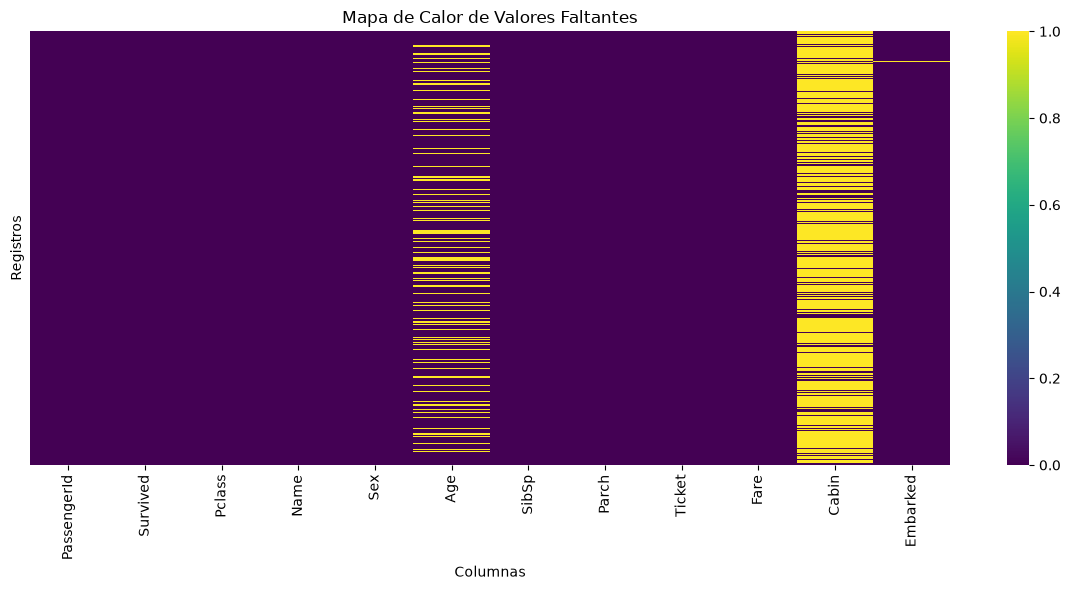

In [6]:

import seaborn as sns
import matplotlib.pyplot as plt

# Crear el mapa de calor de valores nulos
plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=True,
    cmap='viridis',
    yticklabels=False
)

# Personalizar el gráfico
plt.title('Mapa de Calor de Valores Faltantes')
plt.xlabel('Columnas')
plt.ylabel('Registros')

plt.tight_layout()
plt.show()


In [7]:

# Calcular el porcentaje de valores faltantes por columna
missing_values_percentage = (df.isnull().mean() * 100).round(2)

# Ordenar de mayor a menor
missing_values_percentage = missing_values_percentage.sort_values(ascending=False)

# Mostrar resultados
print(missing_values_percentage)


Cabin          77.10
Age            19.87
Embarked        0.22
PassengerId     0.00
Name            0.00
Pclass          0.00
Survived        0.00
Sex             0.00
Parch           0.00
SibSp           0.00
Fare            0.00
Ticket          0.00
dtype: float64


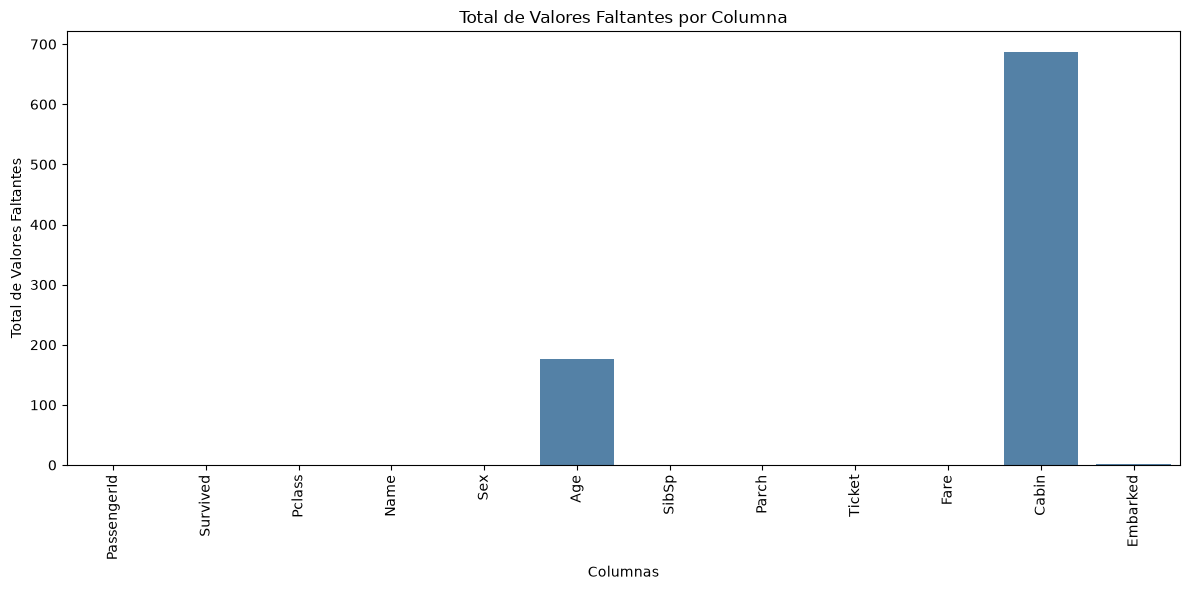

In [8]:

import seaborn as sns
import matplotlib.pyplot as plt

# Calcular el total de valores faltantes por columna
missing_values = df.isnull().sum().reset_index()

# Cambiar los nombres de las columnas
missing_values.columns = ['Columnas', 'Valores Faltantes']

# Crear la gráfica de barras
plt.figure(figsize=(12, 6))

sns.barplot(
    data=missing_values,
    x='Columnas',
    y='Valores Faltantes',
    color='steelblue'
)

# Personalizar la gráfica
plt.title('Total de Valores Faltantes por Columna')
plt.xlabel('Columnas')
plt.ylabel('Total de Valores Faltantes')
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()


In [9]:
df.drop('Cabin', axis = 1, inplace = True)

/tmp/ipykernel_13742/24508361.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop('Cabin', axis = 1, inplace = True)


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(4)
memory usage: 76.7 KB


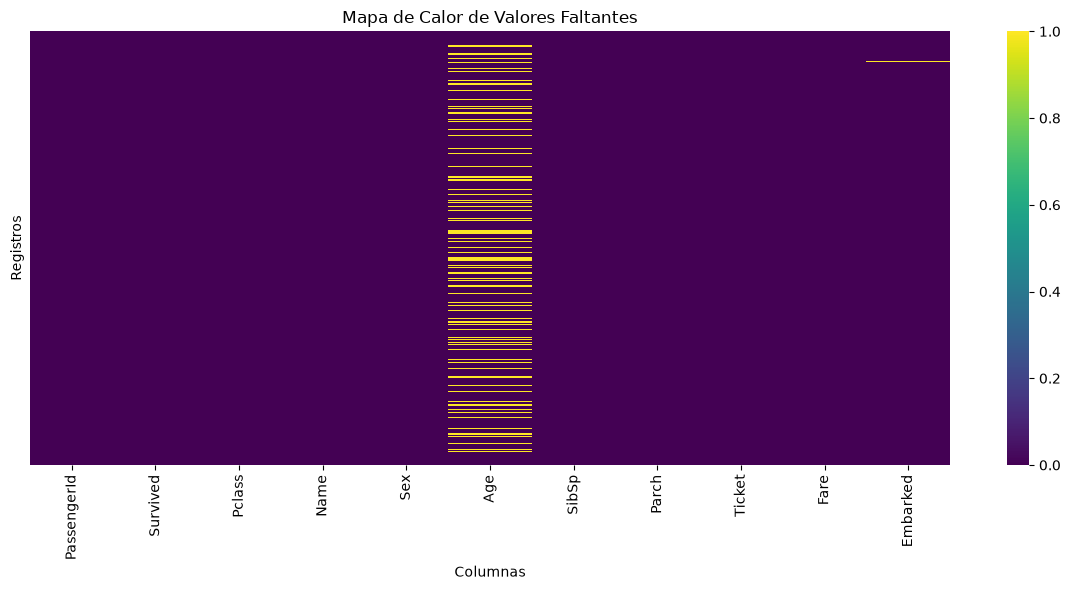

In [11]:

import seaborn as sns
import matplotlib.pyplot as plt

# Crear el mapa de calor de valores nulos
plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=True,
    cmap='viridis',
    yticklabels=False
)

# Personalizar el gráfico
plt.title('Mapa de Calor de Valores Faltantes')
plt.xlabel('Columnas')
plt.ylabel('Registros')

plt.tight_layout()
plt.show()

In [12]:

# Calcular el porcentaje de valores faltantes por columna
missing_values_percentage = (df.isnull().mean() * 100).round(2)

# Ordenar de mayor a menor
missing_values_percentage = missing_values_percentage.sort_values(ascending=False)

# Mostrar resultados
print(missing_values_percentage)

Age            19.87
Embarked        0.22
PassengerId     0.00
Pclass          0.00
Survived        0.00
Sex             0.00
Name            0.00
SibSp           0.00
Parch           0.00
Ticket          0.00
Fare            0.00
dtype: float64


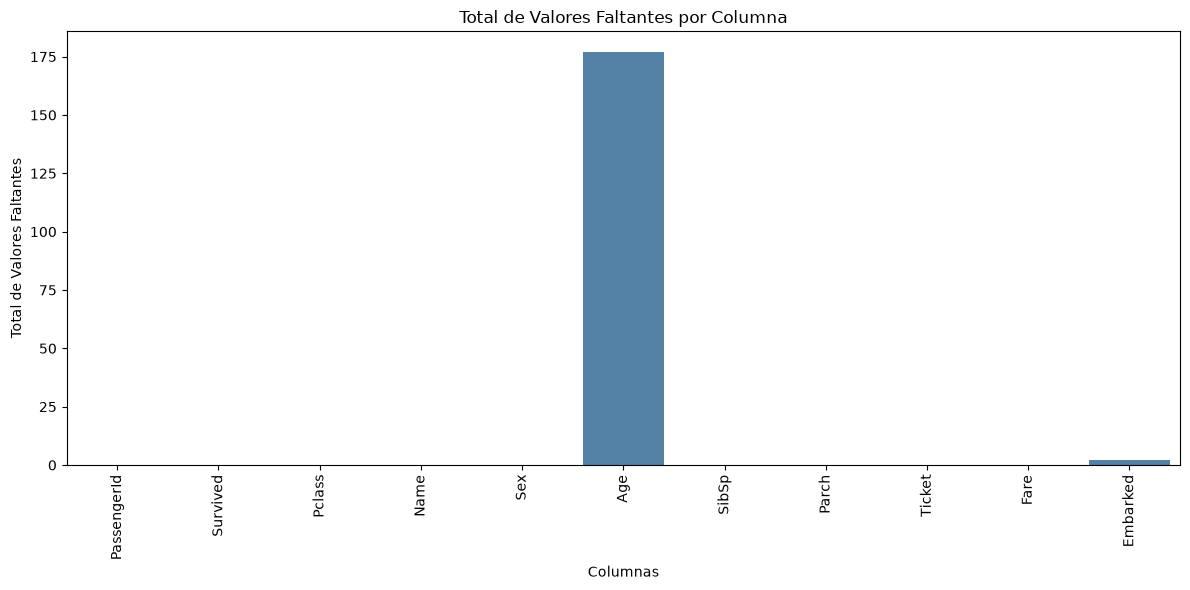

In [13]:

import seaborn as sns
import matplotlib.pyplot as plt

# Calcular el total de valores faltantes por columna
missing_values = df.isnull().sum().reset_index()

# Cambiar los nombres de las columnas
missing_values.columns = ['Columnas', 'Valores Faltantes']

# Crear la gráfica de barras
plt.figure(figsize=(12, 6))

sns.barplot(
    data=missing_values,
    x='Columnas',
    y='Valores Faltantes',
    color='steelblue'
)

# Personalizar la gráfica
plt.title('Total de Valores Faltantes por Columna')
plt.xlabel('Columnas')
plt.ylabel('Total de Valores Faltantes')
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [14]:
# Calcular la mediana de la columna Age
median_age = df['Age'].median()

# Imputar los valores nulos con la mediana
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

In [15]:
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

In [16]:
round(df.isnull().sum().sort_values(ascending = False) / len(df) * 100, 2)

PassengerId    0.0
Survived       0.0
Pclass         0.0
Name           0.0
Sex            0.0
Age            0.0
SibSp          0.0
Parch          0.0
Ticket         0.0
Fare           0.0
Embarked       0.0
dtype: float64

In [17]:
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

In [18]:
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

In [19]:
round(df.isnull().sum().sort_values(ascending = False) / len(df) * 100, 2)

PassengerId    0.0
Survived       0.0
Pclass         0.0
Name           0.0
Sex            0.0
Age            0.0
SibSp          0.0
Parch          0.0
Ticket         0.0
Fare           0.0
Embarked       0.0
dtype: float64

In [20]:
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

In [21]:
df.duplicated().sum()

np.int64(0)

In [22]:
df.drop('Name', axis = 1, inplace = True)
df.drop('Ticket', axis = 1, inplace = True)
df.drop('PassengerId', axis = 1, inplace = True)

/tmp/ipykernel_13742/468766296.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop('Name', axis = 1, inplace = True)
/tmp/ipykernel_13742/468766296.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop('Ticket', axis = 1, inplace = True)
/tmp/ipykernel_13742/468766296.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop('PassengerId', axis = 1, inplace = True)


In [23]:
print(f"Después de limpiar df: {df.shape[0]} filas y {df.shape[1]} columnas.")

Después de limpiar df: 891 filas y 8 columnas.


In [24]:
df.to_csv('./data/titanic_clean.csv', index=False)

In [25]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [26]:
df = pd.read_csv('./data/titanic_clean.csv')

In [27]:
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df.isnull().sum()

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

In [28]:
df.to_csv('./data/titanic_clean.csv', index=False)